## Étape 0 : Chargement et qualité des données
On charge `Train.csv` et on contrôle sa qualité : dimensions, types, valeurs manquantes,
doublons, équilibre de la cible et statistiques des variables numériques.

In [3]:
import pandas as pd 

donnees = pd.read_csv("../data/original/Train.csv") 
print(donnees.shape)  
donnees.head()

(23524, 13)


,country,year,uniqueid,bank_account,location_type,cellphone_access,household_size,age_of_respondent,gender_of_respondent,relationship_with_head,marital_status,education_level,job_type
0,Kenya,2018,uniqueid_1,Yes,Rural,Yes,3,24,Female,Spouse,Married/Living together,Secondary education,Self employed
1,Kenya,2018,uniqueid_2,No,Rural,No,5,70,Female,Head of Household,Widowed,No formal education,Government Dependent
2,Kenya,2018,uniqueid_3,Yes,Urban,Yes,5,26,Male,Other relative,Single/Never Married,Vocational/Specialised training,Self employed
3,Kenya,2018,uniqueid_4,No,Rural,Yes,5,34,Female,Head of Household,Married/Living together,Primary education,Formally employed Private
4,Kenya,2018,uniqueid_5,No,Urban,No,8,26,Male,Child,Single/Never Married,Primary education,Informally employed


In [4]:
donnees.info()

<class 'pandas.DataFrame'>
RangeIndex: 23524 entries, 0 to 23523
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   country                 23524 non-null  str  
 1   year                    23524 non-null  int64
 2   uniqueid                23524 non-null  str  
 3   bank_account            23524 non-null  str  
 4   location_type           23524 non-null  str  
 5   cellphone_access        23524 non-null  str  
 6   household_size          23524 non-null  int64
 7   age_of_respondent       23524 non-null  int64
 8   gender_of_respondent    23524 non-null  str  
 9   relationship_with_head  23524 non-null  str  
 10  marital_status          23524 non-null  str  
 11  education_level         23524 non-null  str  
 12  job_type                23524 non-null  str  
dtypes: int64(3), str(10)
memory usage: 4.6 MB


In [5]:
nombre_manquants = donnees.isna().sum()  # valeurs manquantes par colonne
print(nombre_manquants)

nombre_doublons = donnees.duplicated().sum()  # lignes entièrement identiques
print("Lignes entièrement dupliquées :", nombre_doublons)

identifiants_repetes = donnees["uniqueid"].duplicated().sum()  # identifiants qui reviennent
print("Identifiants répétés :", identifiants_repetes)

couples_repetes = donnees.duplicated(subset=["uniqueid", "country"]).sum()  # couple identifiant + pays 
print("Couples (identifiant, pays) répétés :", couples_repetes)

country                   0
year                      0
uniqueid                  0
bank_account              0
location_type             0
cellphone_access          0
household_size            0
age_of_respondent         0
gender_of_respondent      0
relationship_with_head    0
marital_status            0
education_level           0
job_type                  0
dtype: int64
Lignes entièrement dupliquées : 0
Identifiants répétés : 14789
Couples (identifiant, pays) répétés : 0


In [ ]:
effectifs_cible = donnees["bank_account"].value_counts()  # nombre de Yes et de No
print(effectifs_cible)

pourcentages_cible = donnees["bank_account"].value_counts(normalize=True) * 100  # proportions en %
print(pourcentages_cible.round(2))

bank_account
No     20212
Yes     3312
Name: count, dtype: int64
bank_account
No     85.92 %
Yes    14.08 %
Name: proportion, dtype: str


In [7]:
donnees[["household_size", "age_of_respondent"]].describe().round(2)  # moyenne, min, max, quartiles

,household_size,age_of_respondent
count,23524.00,23524.00
mean,3.80,38.81
std,2.23,16.52
min,1.00,16.00
25%,2.00,26.00
50%,3.00,35.00
75%,5.00,49.00
max,21.00,100.00


In [12]:
pd.crosstab(donnees["country"], donnees["year"])  # nombre de personnes par pays et par année

year,2016,2017,2018
country,,,
Kenya,0,0,6068
Rwanda,8735,0,0
Tanzania,0,6620,0
Uganda,0,0,2101


 On constate que chaque pays n'a qu'une seule année d'enquête

### Conclusions
- Le jeu d'entraînement contient 23 524 lignes et 13 colonnes, sans valeur manquante ni doublons.
- `uniqueid` n'est pas unique seul, mais le couple (`uniqueid`, `country`) l'est.
- La cible est déséquilibrée : 85,92 % de `No` contre 14,08 % de `Yes`.
- L'âge va de 16 à 100 ans et la taille du ménage de 1 à 21.

---

### Etape 1 : Analyse univariée

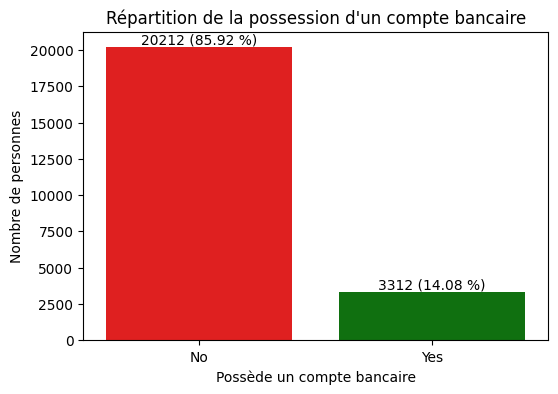

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

couleurs_cible = {"Yes": "green", "No": "red"} 

effectifs_cible = donnees["bank_account"].value_counts()  # nombre de Yes et de No
pourcentages_cible = (effectifs_cible / len(donnees) * 100).round(2)  # part de chaque modalité en %

figure, axe = plt.subplots(figsize=(6, 4))  # crée la figure et un seul graphique
sns.barplot(
    x=effectifs_cible.index,
    y=effectifs_cible.values,
    hue=effectifs_cible.index,  # colore chaque barre selon sa modalité
    palette=couleurs_cible,
    legend=False,
    ax=axe,
)

for position, modalite in enumerate(effectifs_cible.index):  # écrit l'effectif et le % au-dessus de chaque barre
    texte = f"{effectifs_cible[modalite]} ({pourcentages_cible[modalite]} %)"
    axe.text(position, effectifs_cible[modalite], texte, ha="center", va="bottom")

axe.set_title("Répartition de la possession d'un compte bancaire")
axe.set_xlabel("Possède un compte bancaire")
axe.set_ylabel("Nombre de personnes")
plt.show()

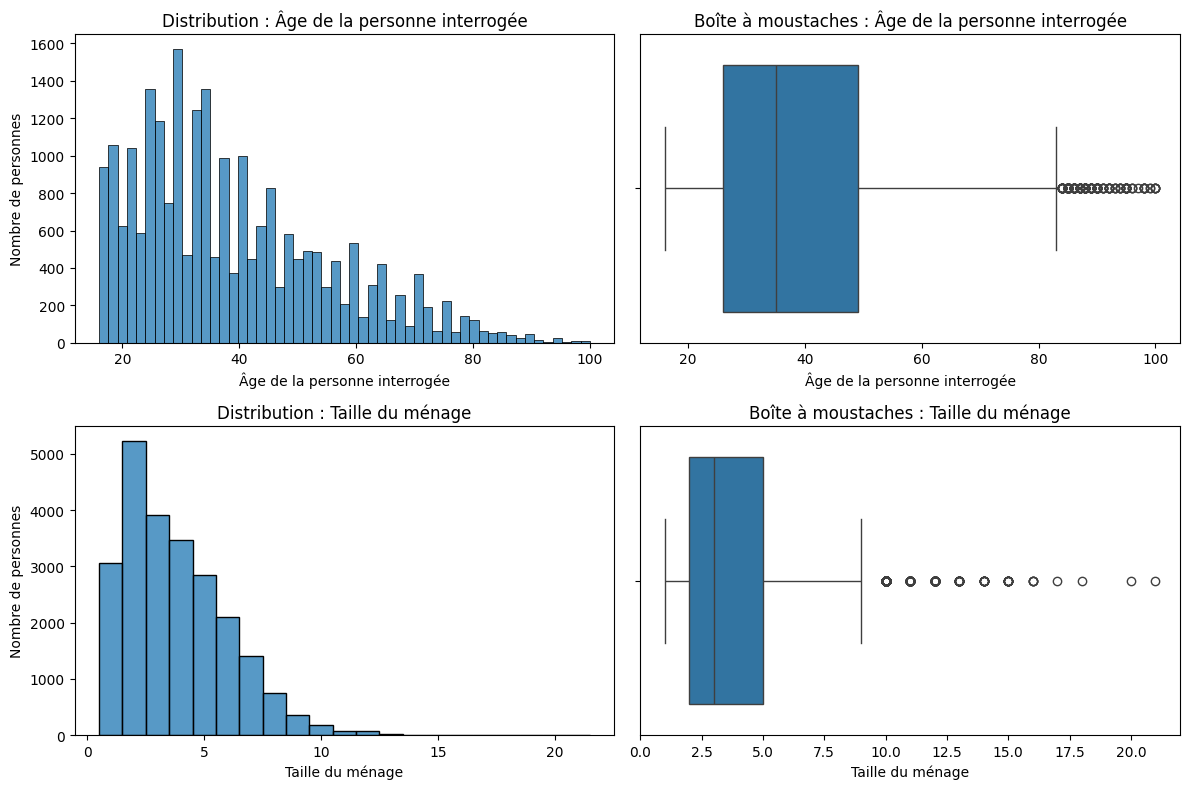

age_of_respondent    0.84
household_size       0.99
dtype: float64

In [16]:
variables_numeriques = ["age_of_respondent", "household_size"]
titres_variables = {
    "age_of_respondent": "Âge de la personne interrogée",
    "household_size": "Taille du ménage",
}

figure, axes = plt.subplots(2, 2, figsize=(12, 8))  # grille : une ligne par variable, histogramme + boîte

for ligne, variable in enumerate(variables_numeriques):
    titre = titres_variables[variable]

    sns.histplot(
        data=donnees,
        x=variable,
        discrete=(variable == "household_size"),  # une barre par valeur entière pour la taille du ménage
        ax=axes[ligne, 0],
    )
    axes[ligne, 0].set_title(f"Distribution : {titre}")
    axes[ligne, 0].set_xlabel(titre)
    axes[ligne, 0].set_ylabel("Nombre de personnes")

    sns.boxplot(data=donnees, x=variable, ax=axes[ligne, 1])  # boîte à moustaches : médiane, quartiles, extrêmes
    axes[ligne, 1].set_title(f"Boîte à moustaches : {titre}")
    axes[ligne, 1].set_xlabel(titre)

plt.tight_layout()  # évite que les titres se chevauchent
plt.show()

donnees[variables_numeriques].skew().round(2)  # asymétrie : > 0 = étalée vers les grandes valeurs

### Interprétation : cible et variables numériques

**Cible (`bank_account`)** : la répartition est très déséquilibrée, 85,92 % de `No` contre 14,08 % de `Yes`.
L'utilisateion de l'accuracy seule serait donc trompeuse

**Âge** : la distribution est étalée vers les grandes valeurs. La majorité des personnes ont entre 20 et 50 ans, avec une médiane d'environ 35 ans.
La boîte à moustaches signale des valeurs extrêmes au-delà d'environ 83 ans, jusqu'à 100.

**Taille du ménage** : la distribution est aussi étalée vers les grandes valeurs, avec un mode de 2 personnes et une médiane de 3.
Les ménages de plus de 9 personnes sont signalés comme extrêmes, jusqu'à 21.

Ces valeurs extrêmes restent plausibles dans une enquête de ménages. On les conserve pour l'instant et on regardera leur effet sur le taux de comptes pendant l'analyse bivarié.

In [ ]:
variables_categorielles = [
    "country", "location_type", "cellphone_access", "gender_of_respondent",
    "relationship_with_head", "marital_status", "education_level", "job_type", "year",
]  

for variable in variables_categorielles:
    pourcentages = donnees[variable].value_counts(normalize=True) * 100  # part de chaque modalité en %
    print(pourcentages.round(2))  # arrondi à 2 décimales
    print()

country
Rwanda      37.13
Tanzania    28.14
Kenya       25.79
Uganda       8.93
Name: proportion, dtype: float64

location_type
Rural    60.97
Urban    39.03
Name: proportion, dtype: float64

cellphone_access
Yes    74.2
No     25.8
Name: proportion, dtype: float64

gender_of_respondent
Female    58.99
Male      41.01
Name: proportion, dtype: float64

relationship_with_head
Head of Household      54.54
Spouse                 27.72
Child                   9.48
Parent                  4.62
Other relative          2.84
Other non-relatives     0.81
Name: proportion, dtype: float64

marital_status
Married/Living together    45.69
Single/Never Married       33.94
Widowed                    11.51
Divorced/Seperated          8.83
Dont know                   0.03
Name: proportion, dtype: float64

education_level
Primary education                  54.37
No formal education                19.19
Secondary education                17.95
Tertiary education                  4.92
Vocational/Specialise

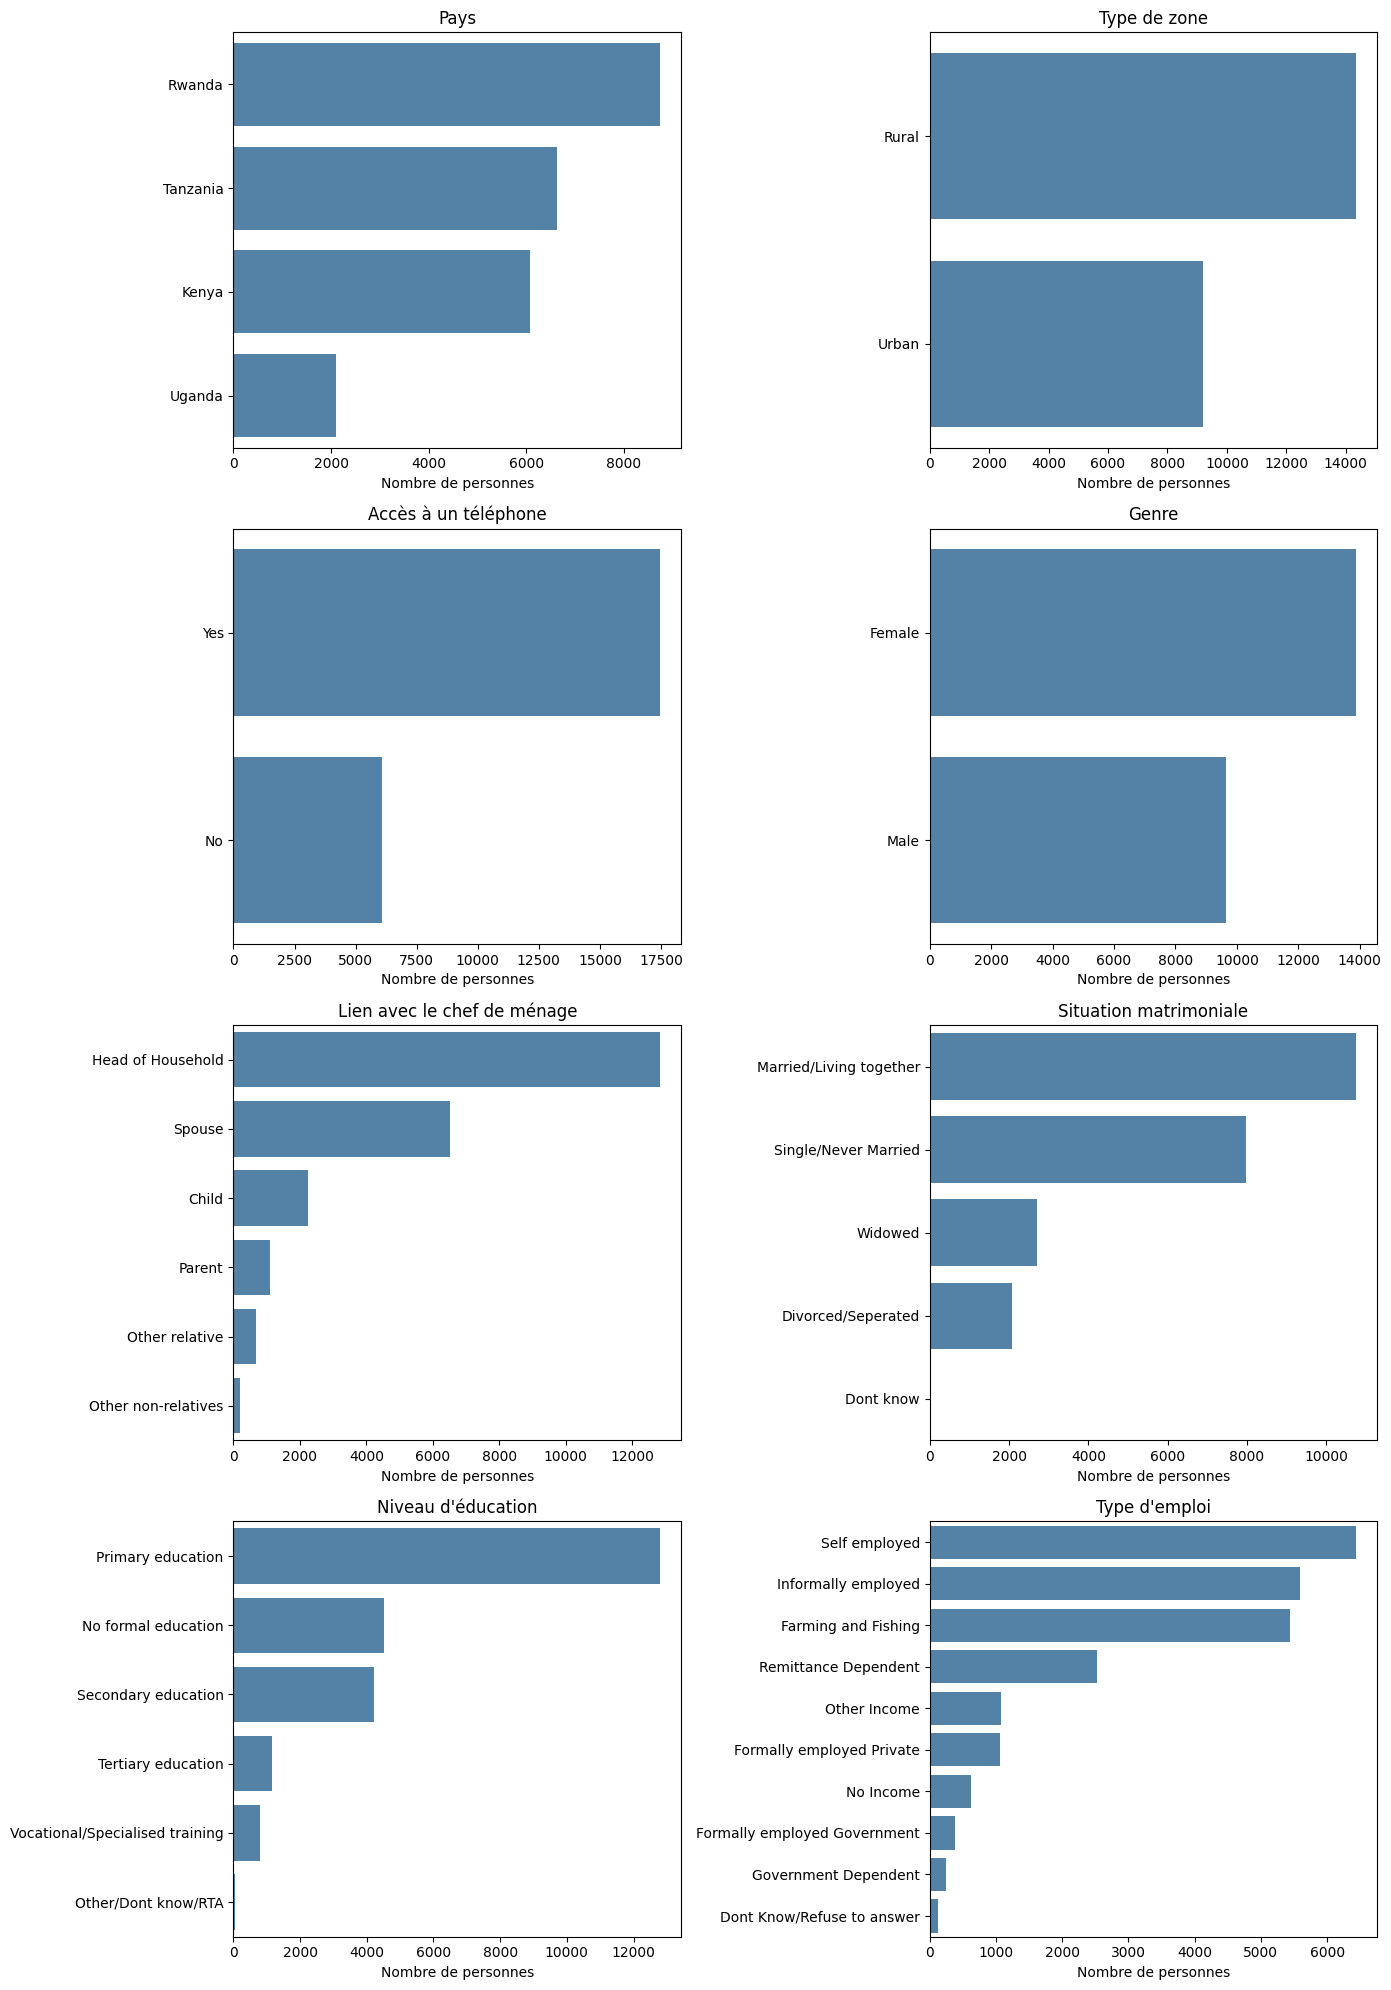

In [19]:
titres_categorielles = {
    "country": "Pays",
    "location_type": "Type de zone",
    "cellphone_access": "Accès à un téléphone",
    "gender_of_respondent": "Genre",
    "relationship_with_head": "Lien avec le chef de ménage",
    "marital_status": "Situation matrimoniale",
    "education_level": "Niveau d'éducation",
    "job_type": "Type d'emploi",
}

figure, axes = plt.subplots(4, 2, figsize=(14, 20))  # grille de 4 lignes x 2 colonnes
axes = axes.flatten()  # transforme la grille en liste simple pour la parcourir

for position, variable in enumerate(variables_categorielles):
    ordre = donnees[variable].value_counts().index  # modalités classées de la plus fréquente à la moins fréquente
    sns.countplot(
        data=donnees,
        y=variable,  # barres horizontales : les libellés longs restent lisibles
        order=ordre,
        color="steelblue",
        ax=axes[position],
    )
    axes[position].set_title(titres_categorielles[variable])
    axes[position].set_xlabel("Nombre de personnes")
    axes[position].set_ylabel("")

plt.tight_layout()
plt.show()

### Interprétation : variables catégorielles

- **Pays** : le Rwanda (37,13 %), la Tanzanie (28,14 %) et le Kenya (25,79 %) dominent l'échantillon, l'Ouganda n'en représente que 8,93 %.
- **Zone et genre** : 60,97 % des personnes vivent en zone rurale et 58,99 % sont des femmes.
- **Téléphone** : 74,2 % ont accès à un téléphone.
- **Lien avec le chef de ménage** : plus de la moitié sont chefs de ménage (54,54 %), suivis des conjoints (27,72 %).
- **Éducation** : l'éducation primaire domine (54,37 %). Les études supérieures (4,92 %) et la formation professionnelle (3,41 %) sont rares.
- **Emploi** : trois catégories regroupent près des trois quarts des personnes : indépendant (27,36 %), emploi informel (23,79 %) et agriculture/pêche (23,13 %). Les emplois formels sont rares : privé 4,48 % et public 1,65 %.
- **Modalités très rares** : « Dont know » en situation matrimoniale (0,03 %) et « Other/Dont know/RTA » en éducation (0,15 %). À regrouper ou à surveiller pour la modélisation.

**Limite (point de vigilance, hors données)** : ces proportions décrivent l'échantillon de l'enquête.
La méthode d'échantillonnage n'est pas documentée dans les fichiers fournis : on ne peut donc pas affirmer qu'elles représentent chaque pays.
Les effectifs très différents selon les pays (Rwanda 37,13 %, Ouganda 8,93 %) suggèrent que l'échantillon ne reflète pas le poids réel de chaque pays.